In [1]:
!pip install kaggle

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: C:\Program Files\Python310\python.exe -m pip install --upgrade pip


In [2]:
# configuring the path of Kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

The syntax of the command is incorrect.
'cp' is not recognized as an internal or external command,
operable program or batch file.
'chmod' is not recognized as an internal or external command,
operable program or batch file.


Importing Face Mask Dataset

In [3]:
# API to fetch the dataset from Kaggle
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
face-mask-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [4]:
# extracting the compessed Dataset
from zipfile import ZipFile
dataset = 'face-mask-dataset.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [5]:
!ls

'ls' is not recognized as an internal or external command,
operable program or batch file.


**Importing the Dependencies**

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
# from google.colab.patches import cv2_imshow
from PIL import Image
from sklearn.model_selection import train_test_split

In [7]:
with_mask_files = os.listdir('data/with_mask')
print(with_mask_files[0:5])
print(with_mask_files[-5:])

['with_mask_1.jpg', 'with_mask_10.jpg', 'with_mask_100.jpg', 'with_mask_1000.jpg', 'with_mask_1001.jpg']
['with_mask_995.jpg', 'with_mask_996.jpg', 'with_mask_997.jpg', 'with_mask_998.jpg', 'with_mask_999.jpg']


In [8]:
without_mask_files = os.listdir('data/without_mask')
print(without_mask_files[0:5])
print(without_mask_files[-5:])

['without_mask_1.jpg', 'without_mask_10.jpg', 'without_mask_100.jpg', 'without_mask_1000.jpg', 'without_mask_1001.jpg']
['without_mask_995.jpg', 'without_mask_996.jpg', 'without_mask_997.jpg', 'without_mask_998.jpg', 'without_mask_999.jpg']


In [9]:
print('Number of with mask images:', len(with_mask_files))
print('Number of without mask images:', len(without_mask_files))

Number of with mask images: 3725
Number of without mask images: 3828


**Creating Labels for the two class of Images**

with mask  -->  1

without mask  -->  0

In [10]:
# create the labels

with_mask_labels = [1]*3725

without_mask_labels = [0]*3828

In [11]:
print(with_mask_labels[0:5])

print(without_mask_labels[0:5])

[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0]


In [12]:
print(len(with_mask_labels))
print(len(without_mask_labels))

3725
3828


In [13]:
labels = with_mask_labels + without_mask_labels

print(len(labels))
print(labels[0:5])
print(labels[-5:])

7553
[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0]


**Displaying the Images**

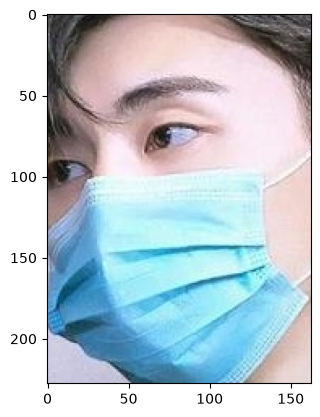

In [14]:
# displaying with mask image
img = mpimg.imread('data/with_mask/with_mask_1545.jpg')
imgplot = plt.imshow(img)
plt.show()

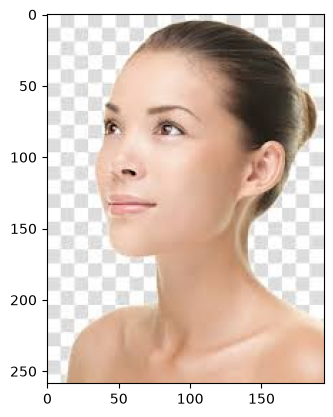

In [15]:
# displaying without mask image
img = mpimg.imread('data/without_mask/without_mask_2925.jpg')
imgplot = plt.imshow(img)
plt.show()

**Image Processing**

1. Resize the Images

2. Convert the images to numpy arrays

In [16]:
# convert images to numpy arrays+

with_mask_path = 'data/with_mask/'

data = []

for img_file in with_mask_files:

  image = Image.open(with_mask_path + img_file)
  image = image.resize((128,128))
  image = image.convert('RGB')
  image = np.array(image)
  data.append(image)



without_mask_path = 'data/without_mask/'


for img_file in without_mask_files:

  image = Image.open(without_mask_path + img_file)
  image = image.resize((128,128))
  image = image.convert('RGB')
  image = np.array(image)
  data.append(image)

C:\Users\shubh\AppData\Roaming\Python\Python312\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [17]:
type(data)

list

In [18]:
len(data)

7553

In [19]:
data[0]

array([[[50, 58, 31],
        [46, 55, 33],
        [56, 58, 42],
        ...,
        [27, 32, 25],
        [29, 33, 19],
        [33, 40, 17]],

       [[47, 54, 30],
        [49, 58, 36],
        [59, 63, 40],
        ...,
        [18, 21, 11],
        [37, 42, 31],
        [31, 41, 23]],

       [[51, 58, 37],
        [50, 59, 37],
        [59, 64, 37],
        ...,
        [45, 44, 30],
        [29, 34, 27],
        [20, 30, 18]],

       ...,

       [[63, 73, 37],
        [66, 75, 41],
        [74, 84, 50],
        ...,
        [ 5,  3,  0],
        [20, 19, 14],
        [17, 16, 12]],

       [[58, 72, 34],
        [60, 70, 39],
        [68, 75, 49],
        ...,
        [16, 15, 12],
        [15, 13, 10],
        [13,  9,  7]],

       [[53, 69, 30],
        [53, 64, 37],
        [57, 64, 42],
        ...,
        [18, 18, 16],
        [16, 13, 12],
        [19, 12, 13]]], shape=(128, 128, 3), dtype=uint8)

In [20]:
type(data[0])

numpy.ndarray

In [21]:
data[0].shape

(128, 128, 3)

In [22]:
# converting image list and label list to numpy arrays

X = np.array(data)
Y = np.array(labels)

In [23]:
type(X)

numpy.ndarray

In [24]:
type(Y)

numpy.ndarray

In [25]:
print(X.shape)
print(Y.shape)

(7553, 128, 128, 3)
(7553,)


In [26]:
print(Y)

[1 1 1 ... 0 0 0]


**Train Test Split**

In [27]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [28]:
print(X.shape, X_train.shape, X_test.shape)

(7553, 128, 128, 3) (6042, 128, 128, 3) (1511, 128, 128, 3)


In [29]:
# scaling the data

X_train_scaled = X_train/255

X_test_scaled = X_test/255

In [30]:
X_train[0]

array([[[226, 234, 201],
        [211, 216, 188],
        [188, 188, 169],
        ...,
        [186, 181, 165],
        [179, 175, 150],
        [166, 181, 136]],

       [[224, 228, 218],
        [201, 204, 195],
        [201, 199, 192],
        ...,
        [197, 190, 182],
        [175, 170, 153],
        [162, 180, 143]],

       [[205, 204, 212],
        [221, 220, 226],
        [195, 192, 196],
        ...,
        [183, 174, 173],
        [172, 167, 159],
        [181, 199, 171]],

       ...,

       [[156, 176, 197],
        [159, 180, 196],
        [164, 185, 196],
        ...,
        [ 89,  99,  71],
        [106, 113,  83],
        [ 99, 103,  68]],

       [[151, 177, 196],
        [167, 190, 208],
        [174, 192, 210],
        ...,
        [106, 113,  80],
        [ 99, 104,  64],
        [ 98,  98,  41]],

       [[162, 192, 210],
        [177, 199, 220],
        [175, 189, 213],
        ...,
        [103, 107,  70],
        [ 79,  80,  46],
        [ 99,  94,  61]]

In [31]:
X_train_scaled[0]

array([[[0.88627451, 0.91764706, 0.78823529],
        [0.82745098, 0.84705882, 0.7372549 ],
        [0.7372549 , 0.7372549 , 0.6627451 ],
        ...,
        [0.72941176, 0.70980392, 0.64705882],
        [0.70196078, 0.68627451, 0.58823529],
        [0.65098039, 0.70980392, 0.53333333]],

       [[0.87843137, 0.89411765, 0.85490196],
        [0.78823529, 0.8       , 0.76470588],
        [0.78823529, 0.78039216, 0.75294118],
        ...,
        [0.77254902, 0.74509804, 0.71372549],
        [0.68627451, 0.66666667, 0.6       ],
        [0.63529412, 0.70588235, 0.56078431]],

       [[0.80392157, 0.8       , 0.83137255],
        [0.86666667, 0.8627451 , 0.88627451],
        [0.76470588, 0.75294118, 0.76862745],
        ...,
        [0.71764706, 0.68235294, 0.67843137],
        [0.6745098 , 0.65490196, 0.62352941],
        [0.70980392, 0.78039216, 0.67058824]],

       ...,

       [[0.61176471, 0.69019608, 0.77254902],
        [0.62352941, 0.70588235, 0.76862745],
        [0.64313725, 0

**Building a Convolutional Neural Networks (CNN)**

In [32]:
import tensorflow as tf
from tensorflow import keras

In [33]:
num_of_classes = 2

model = keras.Sequential()

model.add(keras.layers.Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(128,128,3)))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))


model.add(keras.layers.Conv2D(64, kernel_size=(3,3), activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(64, activation='relu'))
model.add(keras.layers.Dropout(0.5))


model.add(keras.layers.Dense(num_of_classes, activation='sigmoid'))

C:\Users\shubh\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
# compile the neural network
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['acc'])

In [35]:
# training the neural network
history = model.fit(X_train_scaled, Y_train, validation_split=0.1, epochs=5)

Epoch 1/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 59s 332ms/step - acc: 0.7662 - loss: 0.5062 - val_acc: 0.8843 - val_loss: 0.3083
Epoch 2/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 81s 477ms/step - acc: 0.8755 - loss: 0.3229 - val_acc: 0.8975 - val_loss: 0.2551
Epoch 3/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 57s 333ms/step - acc: 0.8977 - loss: 0.2615 - val_acc: 0.9190 - val_loss: 0.2355
Epoch 4/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 48s 281ms/step - acc: 0.9084 - loss: 0.2300 - val_acc: 0.9240 - val_loss: 0.2267
Epoch 5/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 47s 275ms/step - acc: 0.9187 - loss: 0.2026 - val_acc: 0.9322 - val_loss: 0.2169


**Model Evaluation**

In [41]:
loss, accuracy = model.evaluate(X_test_scaled, Y_test)
print('Test Accuracy =', accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - acc: 0.9219 - loss: 0.2124
Test Accuracy = 0.9219059944152832


In [42]:
# Model ko .h5 format me save karne ki command
model.save('mask_model.h5')

print("Model successfully save ho gaya hai!")

Model successfully save ho gaya hai!


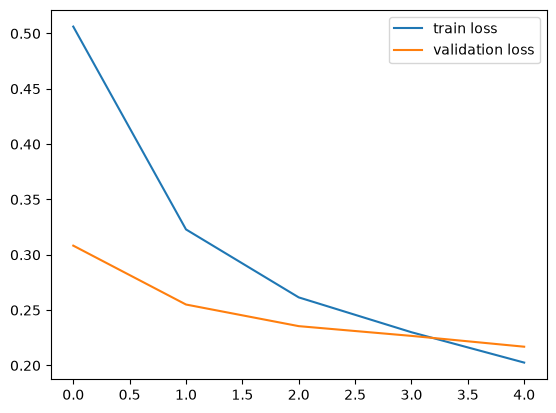

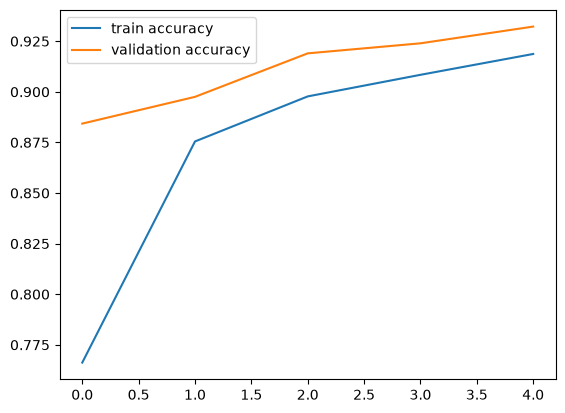

In [43]:
h = history

# plot the loss value
plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

# plot the accuracy value
plt.plot(h.history['acc'], label='train accuracy')
plt.plot(h.history['val_acc'], label='validation accuracy')
plt.legend()
plt.show()

**Predictive System**

In [44]:
# input_image_path = input('Path of the image to be predicted: ')

# input_image = cv2.imread(input_image_path)

# cv2_imshow(input_image)

# input_image_resized = cv2.resize(input_image, (128,128))

# # IMPORTANT FIX: training ke time PIL (Image.open) se RGB images use hui thi,
# # lekin cv2.imread BGR order me image deta hai. Isliye predict karne se pehle
# # BGR -> RGB convert karna zaroori hai, warna prediction ulta/galat aata hai.
# input_image_rgb = cv2.cvtColor(input_image_resized, cv2.COLOR_BGR2RGB)

# input_image_scaled = input_image_rgb/255

# input_image_reshaped = np.reshape(input_image_scaled, [1,128,128,3])

# input_prediction = model.predict(input_image_reshaped)

# print(input_prediction)


# input_pred_label = np.argmax(input_prediction)

# print(input_pred_label)


# if input_pred_label == 1:

#   print('The person in the image is wearing a mask')

# else:

#   print('The person in the image is not wearing a mask')

In [45]:
# input_image_path = input('Path of the image to be predicted: ')

# input_image = cv2.imread(input_image_path)

# cv2_imshow(input_image)

# input_image_resized = cv2.resize(input_image, (128,128))

# # BGR -> RGB fix (see note in previous cell)
# input_image_rgb = cv2.cvtColor(input_image_resized, cv2.COLOR_BGR2RGB)

# input_image_scaled = input_image_rgb/255

# input_image_reshaped = np.reshape(input_image_scaled, [1,128,128,3])

# input_prediction = model.predict(input_image_reshaped)

# print(input_prediction)


# input_pred_label = np.argmax(input_prediction)

# print(input_pred_label)


# if input_pred_label == 1:

#   print('The person in the image is wearing a mask')

# else:

#   print('The person in the image is not wearing a mask')

### Agar Colab ki jagah apne local PC par (VS Code / Jupyter, laptop ke webcam ke saath) chalana hai

Neeche wala cell **Colab me nahi**, balki apne local machine par chalega (jahan `cv2.VideoCapture(0)` seedha laptop ka webcam khol sakta hai).

In [55]:
import os
import cv2
import numpy as np
from tensorflow.keras.models import load_model

# ==========================================
# 1. FIXED FOLDER PATH SETUP
# ==========================================
# Aapka diya gaya exact folder path yahan set kiya gaya hai:
project_folder = r"C:\Users\shubh\OneDrive\Desktop\facemask detection project"

mask_model_path = os.path.join(project_folder, "mask_model.h5") 
prototxt_path = os.path.join(project_folder, "deploy.prototxt")
caffe_model_path = os.path.join(project_folder, "res10_300x300_ssd_iter_140000.caffemodel")

# ==========================================
# 2. SAFETY CHECKS 
# ==========================================
if not os.path.exists(mask_model_path):
    raise FileNotFoundError(f"\n\nERROR: Model nahi mila: {mask_model_path}\n"
                            "Please 'mask_model.h5' ko is folder me save karein.")

if not os.path.exists(prototxt_path) or not os.path.exists(caffe_model_path):
    raise FileNotFoundError(f"\n\nERROR: Caffe files nahi milin!\n"
                            f"Please 'deploy.prototxt' aur '.caffemodel' ko is folder me save karein:\n"
                            f"{project_folder}")

# ==========================================
# 3. LOAD MODELS
# ==========================================
print(f"Files dhoondh raha hai is folder me: {project_folder}")
print("Loading models...")
model = load_model(mask_model_path)
face_net_local = cv2.dnn.readNetFromCaffe(prototxt_path, caffe_model_path)

# ==========================================
# 4. START WEBCAM
# ==========================================
print("Webcam start ho raha hai... Band karne ke liye 'q' dabayein.")
cap = cv2.VideoCapture(0)  # 0 = default webcam

while True:
    ret, frame = cap.read()
    if not ret:
        print("Camera se feed nahi aa rahi. Exiting...")
        break

    h, w = frame.shape[:2]
    # Prepare image for face detection
    blob = cv2.dnn.blobFromImage(frame, 1.0, (300, 300), (104.0, 177.0, 123.0))
    face_net_local.setInput(blob)
    detections = face_net_local.forward()

    for i in range(detections.shape[2]):
        confidence = detections[0, 0, i, 2]
        
        # Filter out weak detections
        if confidence < 0.5:
            continue

        # Calculate bounding box coordinates
        box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
        (x1, y1, x2, y2) = box.astype('int')
        
        # Ensure bounding boxes fall within the frame dimensions
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        face_img = frame[y1:y2, x1:x2]
        if face_img.size == 0:
            continue

        # Prepare face for mask detection model
        face_resized = cv2.resize(face_img, (128, 128))
        face_rgb = cv2.cvtColor(face_resized, cv2.COLOR_BGR2RGB) # BGR -> RGB fix
        face_scaled = face_rgb / 255.0
        face_reshaped = np.reshape(face_scaled, [1, 128, 128, 3])

        # Predict Mask vs No Mask
        prediction = model.predict(face_reshaped, verbose=0)
        pred_label = np.argmax(prediction)

        # Assuming 1 = Mask, 0 = No Mask (Aapke model ke hisaab se adjust karein)
        if pred_label == 1:
            text, color = 'Mask', (0, 255, 0)
        else:
            text, color = 'No Mask', (0, 0, 255)

        # Draw the rectangle and text
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        cv2.putText(frame, text, (x1, max(y1 - 10, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)

    # Show the output
    cv2.imshow('Live Mask Detection - Q dabao band karne ke liye', frame)

    # Quit condition
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Clean up
cap.release()
cv2.destroyAllWindows()

Files dhoondh raha hai is folder me: C:\Users\shubh\OneDrive\Desktop\facemask detection project
Loading models...


Webcam start ho raha hai... Band karne ke liye 'q' dabayein.
